In [1]:
# Import and Configuration 
import torch
import torch.nn as nn
import torchvision.models as models
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from torchvision import transforms
from pathlib import Path

In [2]:
PROJECT_ROOT = Path(r"D:\Pradeep Pandey\Nexvia Technology  Intership\Project 1")

CHECKPOINT_PATH = PROJECT_ROOT / "outputs/models/densenet121_finetuned.pth"
IMAGE_DIR = PROJECT_ROOT / "data/sample/images"

device = torch.device("cpu")

print("Device:", device)
print("Checkpoint exists:", CHECKPOINT_PATH.exists())
print("Image directory exists:", IMAGE_DIR.exists())

Device: cpu
Checkpoint exists: True
Image directory exists: True


In [5]:
#loading fineTUNED Model DenseNet121
model = models.densenet121(weights=None)

model.classifier = nn.Linear(1024, 14)

model.load_state_dict(checkpoint["model_state_dict"])

model = model.to(device)
model.eval()

disease_classes = checkpoint["disease_classes"]

print("Model loaded successfully!")
print("Architecture:", checkpoint["architecture"])
print("Number of classes:", len(disease_classes))
print("Image size:", checkpoint["image_size"])
print("Classes:", disease_classes)

Model loaded successfully!
Architecture: DenseNet121
Number of classes: 14
Image size: 224
Classes: ['Atelectasis', 'Cardiomegaly', 'Effusion', 'Infiltration', 'Mass', 'Nodule', 'Pneumonia', 'Pneumothorax', 'Consolidation', 'Edema', 'Emphysema', 'Fibrosis', 'Pleural_Thickening', 'Hernia']


In [6]:
# Defining GradCam Layer 
target_layer = model.features.denseblock4

print("Grad-CAM target layer:")
print(target_layer)

Grad-CAM target layer:
_DenseBlock(
  (denselayer1): _DenseLayer(
    (norm1): BatchNorm2d(512, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (relu1): ReLU(inplace=True)
    (conv1): Conv2d(512, 128, kernel_size=(1, 1), stride=(1, 1), bias=False)
    (norm2): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (relu2): ReLU(inplace=True)
    (conv2): Conv2d(128, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
  )
  (denselayer2): _DenseLayer(
    (norm1): BatchNorm2d(544, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (relu1): ReLU(inplace=True)
    (conv1): Conv2d(544, 128, kernel_size=(1, 1), stride=(1, 1), bias=False)
    (norm2): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (relu2): ReLU(inplace=True)
    (conv2): Conv2d(128, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
  )
  (densela

In [7]:
#capturing activation and gradient 
activations = None
gradients = None

def forward_hook(module, input, output):
    global activations
    activations = output

def backward_hook(module, grad_input, grad_output):
    global gradients
    gradients = grad_output[0]

forward_handle = target_layer.register_forward_hook(forward_hook)

backward_handle = target_layer.register_full_backward_hook(backward_hook)

print("Forward hook registered:", forward_handle is not None)
print("Backward hook registered:", backward_handle is not None)

Forward hook registered: True
Backward hook registered: True


In [8]:
#select a chest Xray Image 
import random

image_files = list(IMAGE_DIR.glob("*.png"))

selected_image = random.choice(image_files)

print("Selected image:", selected_image.name)
print("Image exists:", selected_image.exists())

Selected image: 00004809_000.png
Image exists: True


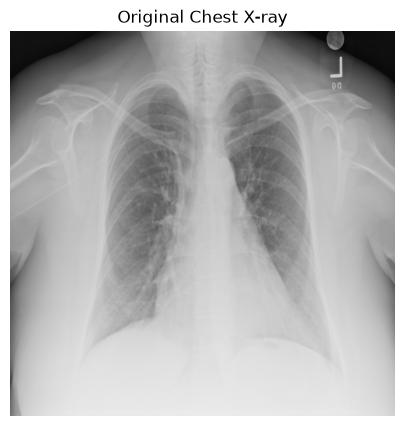

In [9]:
#visualisation
original_image = Image.open(selected_image).convert("RGB")

plt.figure(figsize=(5, 5))
plt.imshow(original_image, cmap="gray")
plt.title("Original Chest X-ray")
plt.axis("off")
plt.show()

In [10]:
#preprocessing the image and get predicitions 
eval_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

input_tensor = eval_transform(original_image).unsqueeze(0).to(device)

with torch.no_grad():
    outputs = model(input_tensor)
    probabilities = torch.sigmoid(outputs)[0]

predicted_idx = torch.argmax(probabilities).item()

predicted_disease = disease_classes[predicted_idx]
predicted_probability = probabilities[predicted_idx].item()

print("Selected disease:", predicted_disease)
print("Probability:", round(predicted_probability, 4))
print("Input shape:", input_tensor.shape)


Selected disease: Atelectasis
Probability: 0.1481
Input shape: torch.Size([1, 3, 224, 224])


In [11]:
#calculationg the gradients
model.zero_grad()


input_tensor.requires_grad_(True)


outputs = model(input_tensor)


target_score = outputs[0, predicted_idx]


target_score.backward()

print("Activations shape:", activations.shape)
print("Gradients shape:", gradients.shape)
print("Target disease:", predicted_disease)
print("Target score:", target_score.item())

Activations shape: torch.Size([1, 1024, 7, 7])
Gradients shape: torch.Size([1, 1024, 7, 7])
Target disease: Atelectasis
Target score: -1.749267578125


In [12]:
#generating the GradCam Heatmap
import torch.nn.functional as F

weights = torch.mean(gradients, dim=(2, 3), keepdim=True)


gradcam = torch.sum(weights * activations, dim=1)


gradcam = torch.relu(gradcam)

gradcam = gradcam - gradcam.min()
gradcam = gradcam / (gradcam.max() + 1e-8)


gradcam = F.interpolate(
    gradcam.unsqueeze(1),
    size=(224, 224),
    mode="bilinear",
    align_corners=False
)

heatmap = gradcam.squeeze().detach().cpu().numpy()

print("Heatmap shape:", heatmap.shape)
print("Minimum:", heatmap.min())
print("Maximum:", heatmap.max())

Heatmap shape: (224, 224)
Minimum: 0.0
Maximum: 0.9843608


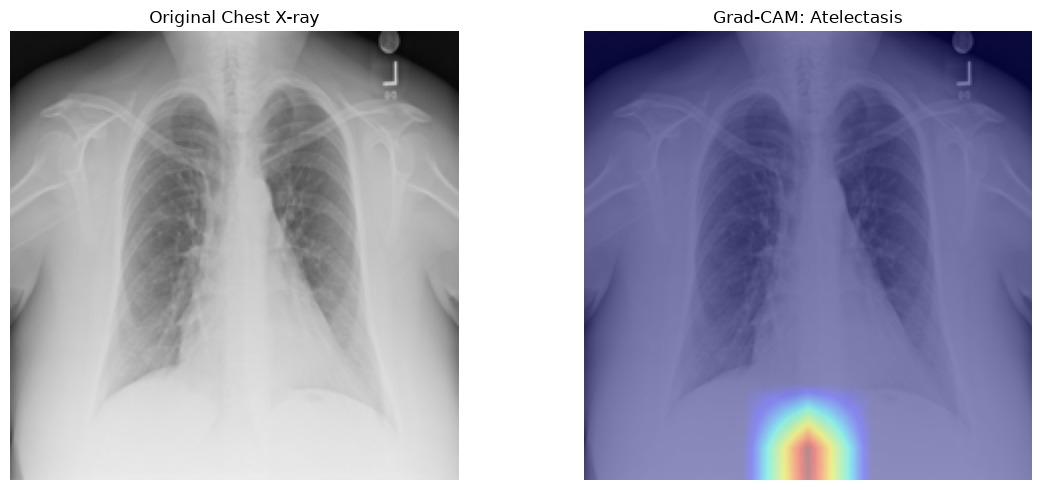

In [13]:
#overlay heatmap on the Orgiginal Image 

display_image = original_image.resize((224, 224))


plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(display_image, cmap="gray")
plt.title("Original Chest X-ray")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(display_image, cmap="gray")
plt.imshow(heatmap, cmap="jet", alpha=0.4)
plt.title(f"Grad-CAM: {predicted_disease}")
plt.axis("off")

plt.tight_layout()
plt.show()

In [14]:
#Saving the result of Gradcam 
OUTPUT_DIR = PROJECT_ROOT / "outputs" / "gradcam"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)


original_image.save(OUTPUT_DIR / "original_xray.png")


plt.imsave(
    OUTPUT_DIR / "gradcam_heatmap.png",
    heatmap,
    cmap="jet"
)


plt.figure(figsize=(6, 6))
plt.imshow(display_image, cmap="gray")
plt.imshow(heatmap, cmap="jet", alpha=0.4)
plt.title(f"Grad-CAM: {predicted_disease}")
plt.axis("off")
plt.savefig(
    OUTPUT_DIR / "gradcam_overlay.png",
    bbox_inches="tight",
    dpi=150
)
plt.close()

print("Saved files:")
for file in OUTPUT_DIR.iterdir():
    print(file.name)

Saved files:
gradcam_heatmap.png
gradcam_overlay.png
original_xray.png


In [17]:
#investigating the results 
import pandas as pd
labels_df = pd.read_csv(
    PROJECT_ROOT / "data/sample/sample_labels.csv"
)

image_info = labels_df[
    labels_df["Image Index"] == selected_image.name
]

positive_images = labels_df[
    labels_df["Finding Labels"].str.contains(
        "Atelectasis",
        regex=False,
        na=False
    )
]

print("Atelectasis-positive images:", len(positive_images))

positive_images[["Image Index", "Finding Labels"]].head(5)

Atelectasis-positive images: 508


,Image Index,Finding Labels
3,00000030_001.png,Atelectasis
29,00000175_001.png,Atelectasis
30,00000175_002.png,Atelectasis
47,00000248_020.png,Atelectasis|Infiltration|Mass|Pleural_Thickening
118,00000642_000.png,Atelectasis


Image exists: True


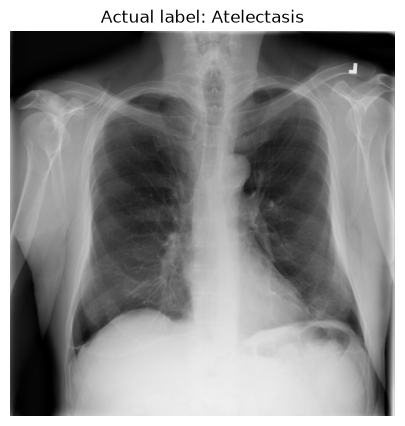

In [18]:
#laoding the positive image Atelectasis
positive_image_name = "00000030_001.png"

positive_image_path = IMAGE_DIR / positive_image_name

print("Image exists:", positive_image_path.exists())

positive_image = Image.open(
    positive_image_path
).convert("RGB")

plt.figure(figsize=(5, 5))
plt.imshow(positive_image, cmap="gray")
plt.title("Actual label: Atelectasis")
plt.axis("off")
plt.show()

In [20]:
#calculating the model probability 
input_tensor = eval_transform(positive_image).unsqueeze(0).to(device)

with torch.no_grad():
    outputs = model(input_tensor)
    probabilities = torch.sigmoid(outputs)[0]

atelectasis_idx = disease_classes.index("Atelectasis")
atelectasis_probability = probabilities[atelectasis_idx].item()

print("Actual label: Atelectasis")
print(f"Model probability: {atelectasis_probability:.4f}")
print("Predicted positive:", atelectasis_probability >= 0.5)

Actual label: Atelectasis
Model probability: 0.0867
Predicted positive: False


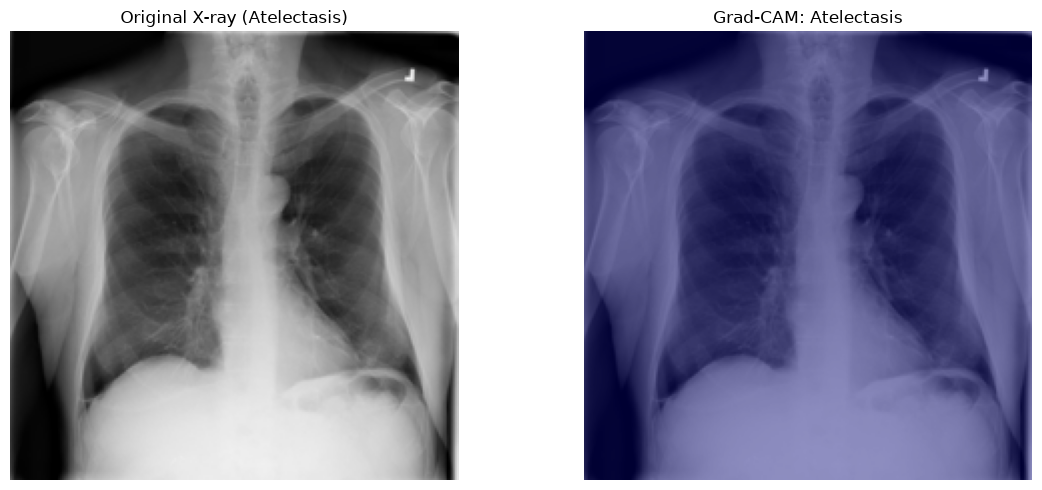

In [22]:
#visualising the original and standard Gradcam image  
display_positive = positive_image.resize((224, 224))

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(display_positive, cmap="gray")
plt.title("Original X-ray (Atelectasis)")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(display_positive, cmap="gray")
plt.imshow(positive_heatmap, cmap="jet", alpha=0.4)
plt.title("Grad-CAM: Atelectasis")
plt.axis("off")

plt.tight_layout()
plt.show()

In [28]:
# Remove the old backward hook anf fresh forward pass
backward_handle.remove()


model.zero_grad()
input_tensor = eval_transform(positive_image).unsqueeze(0).to(device)
input_tensor.requires_grad_(True)

outputs = model(input_tensor)
target_score = outputs[0, atelectasis_idx]


positive_activations = activations
positive_gradients = torch.autograd.grad(
    target_score,
    positive_activations
)[0]

weights = positive_gradients.mean(dim=(2, 3), keepdim=True)

raw_cam_check = torch.sum(
    weights * positive_activations,
    dim=1
)

print("Gradient shape:", positive_gradients.shape)
print("Raw CAM min:", raw_cam_check.min().item())
print("Raw CAM max:", raw_cam_check.max().item())

Gradient shape: torch.Size([1, 1024, 7, 7])
Raw CAM min: -0.05812748521566391
Raw CAM max: -0.010669277980923653


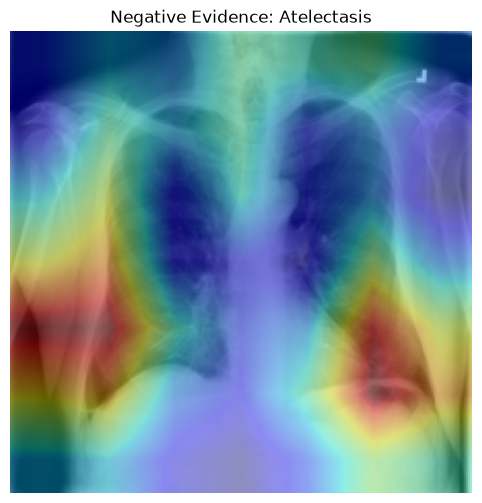

In [26]:
#negaitvinegative image generation 
negative_cam = torch.relu(-raw_cam_check)

negative_cam = negative_cam - negative_cam.min()
negative_cam = negative_cam / (negative_cam.max() + 1e-8)

negative_cam = torch.nn.functional.interpolate(
    negative_cam.unsqueeze(1),
    size=(224, 224),
    mode="bilinear",
    align_corners=False
)

negative_heatmap = negative_cam.squeeze().detach().cpu().numpy()

plt.figure(figsize=(6, 6))
plt.imshow(display_positive, cmap="gray")
plt.imshow(negative_heatmap, cmap="jet", alpha=0.4)
plt.title("Negative Evidence: Atelectasis")
plt.axis("off")
plt.show()

In [29]:
#saving negative evidences
plt.figure(figsize=(6, 6))
plt.imshow(display_positive, cmap="gray")
plt.imshow(negative_heatmap, cmap="jet", alpha=0.4)
plt.title("Negative Evidence: Atelectasis")
plt.axis("off")

plt.savefig(
    OUTPUT_DIR / "gradcam_negative_evidence.png",
    bbox_inches="tight",
    dpi=150
)
plt.close()

print("Saved successfully.")

Saved successfully.


In [ ]:
# Conclusion:- 
#Grad-CAM was implemented to visualize regions influencing DenseNet121 predictions.
#Heatmaps and overlays were generated successfully, while testing revealed limitations in both disease detection and model explainability.